<a href="https://colab.research.google.com/github/antoine-bourgois/MIA_2026_UE16_NLP/blob/main/code/2_Cooccurrence_Tokens_Vecteurs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## TP 3 : Plongement Vectoriel de Documents - Approche Sac de mots (Bag of words)

- Représentation document sac de mots

### Installation des librairies Python utiles pour le TP

In [ ]:
!pip install tqdm jupyter ipywidgets datasets pyarrow huggingface_hub pandas matplotlib numpy scipy scikit-learn umap-learn plotly --quiet

In [2]:
from tqdm.auto import tqdm
from collections import Counter

# Example Basique

In [1]:
! pip install spacy
! python -m spacy download fr_core_news_sm


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1264: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1322: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  r = torch._C._cuda_getDeviceCount() if nvml_count < 0 else nvml_count
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 28.5 MB/s  0:00:00 eta 0:00:01

[notic

In [100]:
import spacy

nlp = spacy.load("fr_core_news_sm", exclude=["parser", "ner"])

def get_tokens(
    data,
    remove_punctuation=True,
    remove_stop_words=True,
    lowercase=True,
    lemmatize=True,
    batch_size=16,
    n_process=4,
):
    def extract(doc):
        tokens = []
        for token in doc:
            if token.is_space:
                continue
            if remove_punctuation and token.is_punct:
                continue
            if remove_stop_words and token.is_stop:
                continue

            word = token.lemma_ if lemmatize else token.text
            if lowercase:
                word = word.lower()
            tokens.append(word)
        return tokens

    # single text: return its token list
    if isinstance(data, str):
        return extract(nlp(data))

    # documents dict: fill in data[title]["tokens"] for every entry
    titles = list(data)
    texts = (data[t]["text"] for t in titles)
    docs = nlp.pipe(texts, batch_size=batch_size, n_process=n_process)

    for title, doc in tqdm(zip(titles, docs), total=len(titles)):
        data[title]["tokens"] = extract(doc)
    return data

In [102]:
documents = {
    "Nvidia" :
        {"text" : "Nvidia est une entreprise spécialisée dans la conception de processeurs graphiques (GPU) et de puces électroniques. Ses technologies sont utilisées dans les jeux vidéo, l'intelligence artificielle et les centres de données."
         },
    "Amazon" :
        {"text" : "Amazon est une entreprise spécialisée dans le commerce en ligne, la vente de produits et les services de livraison. Elle propose également des services de cloud computing grâce à sa plateforme Amazon Web Services (AWS)."
         },
    "Picard" :
        {"text" : "Picard est une entreprise française spécialisée dans la distribution de produits alimentaires surgelés. Elle propose une large gamme de plats préparés, de légumes, de desserts et de produits à cuisiner."
         },
}

documents = get_tokens(documents)

  0%|          | 0/3 [00:00<?, ?it/s]

Process Process-9:
Traceback (most recent call last):
  File "/usr/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/usr/lib/python3.12/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/spacy/language.py", line 2398, in _apply_pipes
    texts_with_ctx = receiver.get()
                     ^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/queues.py", line 103, in get
    res = self._recv_bytes()
          ^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 216, in recv_bytes
    buf = self._recv_bytes(maxlength)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 430, in _recv_bytes
    buf = self._recv(4)
          ^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 395, in _recv
    chunk = read(handle, r

In [103]:
for title, doc_dict in documents.items():
    print(title)
    print(doc_dict["text"])
    print(doc_dict["tokens"])
    print()

Nvidia
Nvidia est une entreprise spécialisée dans la conception de processeurs graphiques (GPU) et de puces électroniques. Ses technologies sont utilisées dans les jeux vidéo, l'intelligence artificielle et les centres de données.
['nvidia', 'entreprise', 'spécialiser', 'conception', 'processeur', 'graphique', 'gpu', 'puce', 'électronique', 'technologie', 'utiliser', 'jeu', 'vidéo', 'intelligence', 'artificiel', 'centre', 'donnée']

Amazon
Amazon est une entreprise spécialisée dans le commerce en ligne, la vente de produits et les services de livraison. Elle propose également des services de cloud computing grâce à sa plateforme Amazon Web Services (AWS).
['amazon', 'entreprise', 'spécialiser', 'commerce', 'ligne', 'vente', 'produit', 'service', 'livraison', 'proposer', 'service', 'cloud', 'computing', 'grâce', 'plateform', 'amazon', 'web', 'service', 'aw']

Picard
Picard est une entreprise française spécialisée dans la distribution de produits alimentaires surgelés. Elle propose une l

## Construire la matrice document x sac de mots

In [104]:
from collections import Counter
import pandas as pd

bow_df = pd.DataFrame.from_dict(
    {
        title: Counter(doc_dict["tokens"])
        for title, doc_dict in documents.items()
    },
    orient="index"
).fillna(0).astype(int)

bow_df = bow_df[bow_df.sum().sort_values(ascending=False).index]

bow_df

,entreprise,spécialiser,produit,service,amazon,proposer,gpu,conception,processeur,graphique,...,distribution,alimentaire,surgeler,large,gamme,plat,préparer,légume,dessert,cuisiner
Nvidia,1,1,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
Amazon,1,1,1,3,2,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Picard,1,1,2,0,0,1,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1


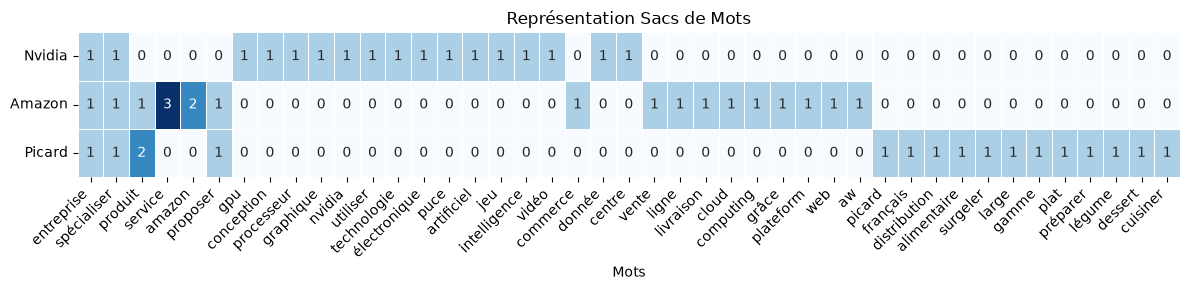

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 3))

sns.heatmap(
    bow_df,
    annot=True,
    cmap="Blues",
    linewidths=0.5,
    cbar=False
)

plt.title("Représentation Sacs de Mots")
plt.xlabel("Mots")
plt.ylabel("")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0, ha="right")
plt.tight_layout()
plt.show()

## TF-IDF (Term Frequency – Inverse Document Frequency)

### TF (Term Frequency) : fréquence du terme dans un document

Dans cette étape, nous calculons la fréquence relative de chaque mot dans chaque document.

In [106]:
tf = bow_df.div(bow_df.sum(axis=1), axis=0)

tf

,entreprise,spécialiser,produit,service,amazon,proposer,gpu,conception,processeur,graphique,...,distribution,alimentaire,surgeler,large,gamme,plat,préparer,légume,dessert,cuisiner
Nvidia,0.058824,0.058824,0.000000,0.000000,0.000000,0.000000,0.058824,0.058824,0.058824,0.058824,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Amazon,0.052632,0.052632,0.052632,0.157895,0.105263,0.052632,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Picard,0.058824,0.058824,0.117647,0.000000,0.000000,0.058824,0.000000,0.000000,0.000000,0.000000,...,0.058824,0.058824,0.058824,0.058824,0.058824,0.058824,0.058824,0.058824,0.058824,0.058824


### IDF (Inverse Document Frequency) : fréquence inverse du document

L'IDF permet de mesurer à quel point un mot est rare ou fréquent dans l'ensemble de notre collection de documents.

In [107]:
import numpy as np

# Nombre total de documents
N = len(bow_df)

# Nombre de documents contenant chaque mot
df = (bow_df > 0).sum(axis=0)

# Conversion en DataFrame
df = df.to_frame(name="Documents")

df.T

,entreprise,spécialiser,produit,service,amazon,proposer,gpu,conception,processeur,graphique,...,distribution,alimentaire,surgeler,large,gamme,plat,préparer,légume,dessert,cuisiner
Documents,3,3,2,1,1,2,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [108]:
# Calcul de l'IDF
idf = np.log(N / df["Documents"])

# Conversion en DataFrame
idf = idf.to_frame(name="IDF")

idf.index.name = "Mot"

idf.T

Mot,entreprise,spécialiser,produit,service,amazon,proposer,gpu,conception,processeur,graphique,...,distribution,alimentaire,surgeler,large,gamme,plat,préparer,légume,dessert,cuisiner
IDF,0.0,0.0,0.405465,1.098612,1.098612,0.405465,1.098612,1.098612,1.098612,1.098612,...,1.098612,1.098612,1.098612,1.098612,1.098612,1.098612,1.098612,1.098612,1.098612,1.098612


In [109]:
tfidf_df = tf.mul(idf["IDF"], axis=1)

tfidf_df = tfidf_df.T
tfidf_df

,Nvidia,Amazon,Picard
entreprise,0.000000,0.000000,0.000000
spécialiser,0.000000,0.000000,0.000000
produit,0.000000,0.021340,0.047702
service,0.000000,0.173465,0.000000
amazon,0.000000,0.115643,0.000000
proposer,0.000000,0.021340,0.023851
gpu,0.064624,0.000000,0.000000
conception,0.064624,0.000000,0.000000
processeur,0.064624,0.000000,0.000000
graphique,0.064624,0.000000,0.000000


In [110]:
for column in tfidf_df:
    sorted_words = tfidf_df.sort_index().sort_values(
        by=column,
        ascending=False,
        kind="stable"
    )

    print(f"{column}:")
    print(f"Mots-clés : {sorted_words.index.tolist()[:5]}")
    print()

Nvidia:
Mots-clés : ['artificiel', 'centre', 'conception', 'donnée', 'gpu']

Amazon:
Mots-clés : ['service', 'amazon', 'aw', 'cloud', 'commerce']

Picard:
Mots-clés : ['alimentaire', 'cuisiner', 'dessert', 'distribution', 'français']



### Utiliser TfidfVectorizer de scikit-learn

Scikit-learn propose une classe appelée `TfidfVectorizer` qui permet de calculer automatiquement les poids TF-IDF à partir d'une collection de documents.

In [111]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Récupération des tokens de chaque document
texts = [
    doc_dict["tokens"]
    for title, doc_dict in documents.items()
]

vectorizer = TfidfVectorizer(
    analyzer=lambda tokens: tokens
)

In [112]:
X_tfidf = vectorizer.fit_transform(texts)

In [113]:
tfidf_sklearn = pd.DataFrame(
    X_tfidf.toarray(),
    index=documents.keys(),
    columns=vectorizer.get_feature_names_out()
)

tfidf_sklearn = tfidf_sklearn.T
tfidf_sklearn

,Nvidia,Amazon,Picard
alimentaire,0.000000,0.000000,0.253269
amazon,0.000000,0.401169,0.000000
artificiel,0.252396,0.000000,0.000000
aw,0.000000,0.200585,0.000000
centre,0.252396,0.000000,0.000000
cloud,0.000000,0.200585,0.000000
commerce,0.000000,0.200585,0.000000
computing,0.000000,0.200585,0.000000
conception,0.252396,0.000000,0.000000
cuisiner,0.000000,0.000000,0.253269


In [114]:
for column in tfidf_sklearn:
    sorted_words = tfidf_sklearn.sort_index().sort_values(
        by=column,
        ascending=False,
        kind="stable"
    )

    print(f"{column}:")
    print(f"Mots-clés : {sorted_words.index.tolist()[:5]}")
    print()

Nvidia:
Mots-clés : ['artificiel', 'centre', 'conception', 'donnée', 'gpu']

Amazon:
Mots-clés : ['service', 'amazon', 'aw', 'cloud', 'commerce']

Picard:
Mots-clés : ['produit', 'alimentaire', 'cuisiner', 'dessert', 'distribution']



In [115]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Extract tokenized documents
texts = [doc["tokens"] for doc in documents.values()]

# Compute TF-IDF
vectorizer = TfidfVectorizer(analyzer=lambda x: x)

X_tfidf = vectorizer.fit_transform(texts)

# Create DataFrame
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    index=documents.keys(),
    columns=vectorizer.get_feature_names_out()
)

In [116]:
def extract_keywords(tfidf_df, top_n=5):
    results = {}

    for doc in tfidf_df.index:
        results[doc] = (
            tfidf_df.loc[doc]
            .sort_values(ascending=False, kind="stable")
            .head(top_n)
            .index.tolist()
        )

    return results

keywords = extract_keywords(tfidf_df, top_n=10)

keywords

{'Nvidia': ['artificiel',
  'centre',
  'conception',
  'donnée',
  'gpu',
  'graphique',
  'intelligence',
  'jeu',
  'nvidia',
  'processeur'],
 'Amazon': ['service',
  'amazon',
  'aw',
  'cloud',
  'commerce',
  'computing',
  'grâce',
  'ligne',
  'livraison',
  'plateform'],
 'Picard': ['produit',
  'alimentaire',
  'cuisiner',
  'dessert',
  'distribution',
  'français',
  'gamme',
  'large',
  'légume',
  'picard']}

In [ ]:
import re
import requests
from urllib.parse import unquote

HEADERS = {"User-Agent": "company-corpus/0.1 (your-email@example.com)"}
API = "https://fr.wikipedia.org/w/api.php"

urls = {
    "Nvidia": "https://fr.wikipedia.org/wiki/Nvidia",
    "Amazon": "https://fr.wikipedia.org/wiki/Amazon",
    "Picard": "https://fr.wikipedia.org/wiki/Picard_Surgel%C3%A9s",
}

CUT = re.compile(
    r"\n==+ *(Notes et références|Références|Voir aussi|Liens externes|Bibliographie|Notes) *==+",
    re.I,
)

def title_from_url(url):
    return unquote(url.rsplit("/wiki/", 1)[1]).replace("_", " ")

def fetch_text(title):
    params = {
        "action": "query",
        "prop": "extracts",
        "explaintext": 1,
        "redirects": 1,
        "titles": title,
        "format": "json",
        "formatversion": 2,
    }
    r = requests.get(API, params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    return r.json()["query"]["pages"][0].get("extract", "")

def clean(text):
    m = CUT.search(text)
    if m:
        text = text[: m.start()]
    text = re.sub(r"\n?==+[^=\n]+==+\n?", "\n", text)
    return re.sub(r"\s+", " ", text).strip()

documents = {
    name: {"text": clean(fetch_text(title_from_url(url)))}
    for name, url in urls.items()
}

documents = get_tokens(documents)

In [118]:
query = """Quelle est l'entreprise la plus similaire à AMD ?
Advanced Micro Devices (AMD) est un fabricant américain de semi-conducteurs, microprocesseurs et cartes graphiques basé à Santa Clara (Californie). La compagnie est fondée le 1er mai 1969 par un groupe d'ingénieurs et de dirigeants de Fairchild Semiconductor. Les cofondateurs d'AMD sont Jerry Sanders, Edwin Turney (en), John Carey, Sven Simonsen, Jack Gifford, Frank Botte, Jim Giles et Larry Stenger. La flèche du logotype de la compagnie dirigée vers la droite symbolise sa croissance dans le « droit chemin » (« the right way »).

En 2006, AMD se situe à la 8e place des 20 plus grands fabricants de semi-conducteurs, derrière Intel, Samsung, Texas Instruments, Toshiba, STMicroelectronics, Renesas et Hynix. Au premier trimestre 2007, la AMD chute à la 18e place de ce classement[7]. Il est par contre le deuxième fournisseur de microprocesseurs pour ordinateur PC à architecture x86, après Intel.
"""

query_tokens = get_tokens(query)
print(query_tokens)
query_vector = vectorizer.transform([query_tokens])
print(query_vector.shape)

['entreprise', 'similaire', 'amd', 'advanced', 'micro', 'devices', 'amd', 'fabricant', 'américain', 'semi-conducteur', 'microprocesseur', 'carte', 'graphique', 'baser', 'santa', 'clara', 'californie', 'compagnie', 'fonder', 'premier', 'mai', '1969', 'groupe', 'ingénieur', 'dirigeant', 'fairchild', 'semiconductor', 'cofondateur', 'amd', 'jerry', 'sanders', 'edwin', 'turney', 'john', 'carey', 'sven', 'simonsen', 'jack', 'gifford', 'frank', 'botte', 'jim', 'giles', 'larry', 'stenger', 'flèche', 'logotype', 'compagnie', 'diriger', 'droite', 'symboliser', 'croissance', 'droit', 'chemin', 'the', 'right', 'way', '2006', 'amd', 'situer', 'huitième', 'place', '20', 'grand', 'fabricant', 'semi-conducteur', 'intel', 'samsung', 'texas', 'instrument', 'toshiba', 'stmicroelectronics', 'renesas', 'hynix', 'trimestre', '2007', 'amd', 'chute', '18', 'place', 'classement[7].', 'contre', 'fournisseur', 'microprocesseur', 'ordinateur', 'pc', 'architecture', 'x86', 'intel']
(1, 43)


In [119]:
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(query_vector, X_tfidf).flatten()

import pandas as pd

results = pd.DataFrame({
    "Document": documents.keys(),
    "Score": similarities
})

results = results.sort_values("Score", ascending=False)

results

,Document,Score
0,Nvidia,0.293130
2,Picard,0.076070
1,Amazon,0.060246


## Exercice : Construire un moteur de recherche lexical à partir des pages wikipedia des entreprises côtées en bourse

- Importer le dataset [`AntoineBourgois/wikipedia-companies`](https://huggingface.co/datasets/AntoineBourgois/wikipedia-companies)
- Décrire succintement le dataset (nombre de documents, champs de chaque document, longueur des descriptions)
- Formater le dataset pour correspondre au format : documents = {}

In [138]:
from datasets import load_dataset

dataset = load_dataset("AntoineBourgois/wikipedia-companies", split="train")
dataset = list(dataset)

In [139]:
dataset = dataset[:500]

In [140]:
dataset[0]

{'qid': 'Q102673',
 'title': 'Gazprom',
 'text': "Gazprom (en cyrillique : Газпро́м) est une société anonyme russe connue principalement pour l'extraction, le traitement et le transport de gaz naturel. Depuis 2005, elle est aussi un acteur majeur sur le marché mondial du pétrole. Son nom est l'acronyme de Gazovaïa Promychlennost, qui signifie « Industrie gazière » en russe. En 2007, c'est la première entreprise russe, la 5e par la capitalisation boursière au monde, derrière Saudi Aramco, TotalEnergies, ExxonMobil et PetroChina et la première valorisation boursière d'Europe. En décembre 2008, à la suite de la crise financière de 2008 entre autres, sa capitalisation boursière a diminué de 76 % par rapport à son sommet, la faisant passer à 85 milliards de dollars, la positionnant ainsi au 35e rang mondial, avant de revenir au 15e rang mondial en 2012. En 2014, Gazprom est classée comme étant le deuxième plus gros investisseur du monde, avec 44,5 milliards de dollars d'investissements. En 

In [141]:
documents = {doc["title"]: {"qid": doc["qid"],
                            "text": doc["text"]} for doc in dataset}

In [142]:
len(documents)

500

In [143]:
documents = get_tokens(documents, n_process=8)

  0%|          | 0/500 [00:00<?, ?it/s]

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Extract tokenized documents
texts = [doc["tokens"] for doc in documents.values()]

# Compute TF-IDF
vectorizer = TfidfVectorizer(analyzer=lambda x: x)

X_tfidf = vectorizer.fit_transform(texts)

# Create DataFrame
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    index=documents.keys(),
    columns=vectorizer.get_feature_names_out()
)


def extract_keywords(tfidf_df, top_n=5):
    results = {}

    for doc in tfidf_df.index:
        results[doc] = (
            tfidf_df.loc[doc]
            .sort_values(ascending=False, kind="stable")
            .head(top_n)
            .index.tolist()
        )

    return results


keywords = extract_keywords(tfidf_df, top_n=5)

keywords

In [136]:
import umap
import pandas as pd
import plotly.express as px

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=10,
    metric="cosine",
    random_state=42
)

embedding = reducer.fit_transform(X_tfidf)

umap_df = pd.DataFrame(
    embedding,
    index=documents.keys(),
    columns=["x", "y"]
)
umap_df["title"] = umap_df.index

fig = px.scatter(
    umap_df,
    x="x",
    y="y",
    hover_name="title",
    title="Document visualization using UMAP",
    labels={"x": "UMAP 1", "y": "UMAP 2"},
    width=1000,
    height=700,
)
fig.update_traces(marker=dict(size=6, opacity=0.7))
fig.show()

/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/antoine/cours/DAUPHINE_2026-2027/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [137]:
query = """Quelle est l'entreprise la plus similaire à AMD ?
Advanced Micro Devices (AMD) est un fabricant américain de semi-conducteurs, microprocesseurs et cartes graphiques basé à Santa Clara (Californie). La compagnie est fondée le 1er mai 1969 par un groupe d'ingénieurs et de dirigeants de Fairchild Semiconductor. Les cofondateurs d'AMD sont Jerry Sanders, Edwin Turney (en), John Carey, Sven Simonsen, Jack Gifford, Frank Botte, Jim Giles et Larry Stenger. La flèche du logotype de la compagnie dirigée vers la droite symbolise sa croissance dans le « droit chemin » (« the right way »).

En 2006, AMD se situe à la 8e place des 20 plus grands fabricants de semi-conducteurs, derrière Intel, Samsung, Texas Instruments, Toshiba, STMicroelectronics, Renesas et Hynix. Au premier trimestre 2007, la AMD chute à la 18e place de ce classement[7]. Il est par contre le deuxième fournisseur de microprocesseurs pour ordinateur PC à architecture x86, après Intel.
"""

query_tokens = get_tokens(query)
print(query_tokens)
query_vector = vectorizer.transform([query_tokens])
print(query_vector.shape)
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(query_vector, X_tfidf).flatten()

import pandas as pd

results = pd.DataFrame({
    "Document": documents.keys(),
    "Score": similarities
})

results = results.sort_values("Score", ascending=False)

results

['entreprise', 'similaire', 'amd', 'advanced', 'micro', 'devices', 'amd', 'fabricant', 'américain', 'semi-conducteur', 'microprocesseur', 'carte', 'graphique', 'baser', 'santa', 'clara', 'californie', 'compagnie', 'fonder', 'premier', 'mai', '1969', 'groupe', 'ingénieur', 'dirigeant', 'fairchild', 'semiconductor', 'cofondateur', 'amd', 'jerry', 'sanders', 'edwin', 'turney', 'john', 'carey', 'sven', 'simonsen', 'jack', 'gifford', 'frank', 'botte', 'jim', 'giles', 'larry', 'stenger', 'flèche', 'logotype', 'compagnie', 'diriger', 'droite', 'symboliser', 'croissance', 'droit', 'chemin', 'the', 'right', 'way', '2006', 'amd', 'situer', 'huitième', 'place', '20', 'grand', 'fabricant', 'semi-conducteur', 'intel', 'samsung', 'texas', 'instrument', 'toshiba', 'stmicroelectronics', 'renesas', 'hynix', 'trimestre', '2007', 'amd', 'chute', '18', 'place', 'classement[7].', 'contre', 'fournisseur', 'microprocesseur', 'ordinateur', 'pc', 'architecture', 'x86', 'intel']
(1, 5731)


,Document,Score
20,Wingtech,0.066199
9,Bull (entreprise),0.061598
8,China Pacific Insurance,0.054099
7,Build-A-Bear Workshop,0.048502
18,Capgemini,0.043898
6,Buffalo Technology,0.042696
24,WestJet Airlines,0.041409
30,Sokon,0.040944
17,Canfor,0.038843
27,Rumble (entreprise),0.038000
